## Project Atlas: Inventory Flow Command Center
## Prepared For: Manager, Advanced Analytics - Inventory Flow

## Objective: Develop an end-to-end analytics platform that improves inventory visibility, forecasting, replenishment decisions, and operational performance.

## Author: [Robert Turner]

## Project Overview


## Business Problem
## Large retail organizations must balance:

## Product Availability
## Inventory Cost
## Demand Variability
## Supply Chain Efficiency
## Poor inventory decisions lead to:

## Stockouts
## Lost Sales
## Excess Carrying Cost
## Reduced Customer Satisfaction
## This project demonstrates how analytics can be used to support inventory flow decisions.

In [3]:
## Data Overview

import pandas as pd

df = pd.read_csv("retail_store_inventory.csv")

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")

df.head()

Rows: 73,100
Columns: 15


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [4]:
## Solution Architecture
## Raw Inventory Data ↓ Data Warehouse ↓ Executive KPI Layer ↓ Supply Chain Insights ↓ Demand Forecasting ↓ Decision Support Dashboard

In [5]:
## Executive KPIs

import sqlite3

db_path = r"C:\Users\bturn\PycharmProjects\bturner\Inventory_Flow_Command_Center\inventory_flow.db"

conn = sqlite3.connect(db_path)

kpi_summary = pd.read_sql("""
SELECT
    COUNT(DISTINCT "Store ID") AS Total_Stores,
    COUNT(DISTINCT "Product ID") AS Total_Products,
    SUM("Units Sold") AS Total_Units_Sold,
    AVG("Inventory Level") AS Avg_Inventory
FROM fact_inventory
""", conn)

kpi_summary

,Total_Stores,Total_Products,Total_Units_Sold,Avg_Inventory
0,5,20,9975582,274.469877


In [6]:
## Key Findings

## Inventory performance varies significantly by region.
## Several categories exhibit elevated stockout exposure.
## Inventory levels are not always aligned with demand.
## Forecasting identifies future replenishment risks.
## Opportunity exists to improve inventory productivity.

In [7]:
## Regional Analysis

regional_analysis = pd.read_sql("""
SELECT
    Region,
    SUM("Units Sold") AS Units_Sold,
    AVG("Inventory Level") AS Avg_Inventory
FROM fact_inventory
GROUP BY Region
ORDER BY Units_Sold DESC
""", conn)

regional_analysis

,Region,Units_Sold,Avg_Inventory
0,East,2511265,275.292659
1,South,2507799,275.313221
2,North,2484966,274.796632
3,West,2471552,272.468122


In [8]:
## Forecasting Benefits

## Inventory forecasting enables:

## Earlier replenishment decisions
## Reduced stockout frequency
## Better inventory allocation
## Increased sales capture
## Improved customer satisfaction

In [18]:
## Business Recommendations

## Recommendations
## Increase replenishment frequency in high-risk regions.
## Reallocate excess inventory from low-demand locations.
## Improve safety stock settings for vulnerable categories.
## Use forecasting outputs within replenishment planning.
## Expand executive KPI monitoring.

In [10]:
## Expected Business Impact
## Expected Outcomes
## Operational Benefits:

## Improved In-Stock Percentage
## Reduced Stockouts
## Faster Inventory Recovery
## Financial Benefits:

## Improved Inventory Productivity
## Lower Holding Costs
## Increased Revenue Retention
## Customer Benefits:

## Improved Product Availability
## Improved Shopping Experience

In [11]:
## Closing Statement

# Executive Summary
## Project Atlas demonstrates an end-to-end inventory analytics framework capable of supporting retail inventory flow decisions.

## The solution integrates:

## Data Engineering
## SQL Analytics
## Executive KPI Reporting
## Business Insights
## Inventory Forecasting
## The result is a scalable decision-support platform designed to improve inventory productivity and operational performance.

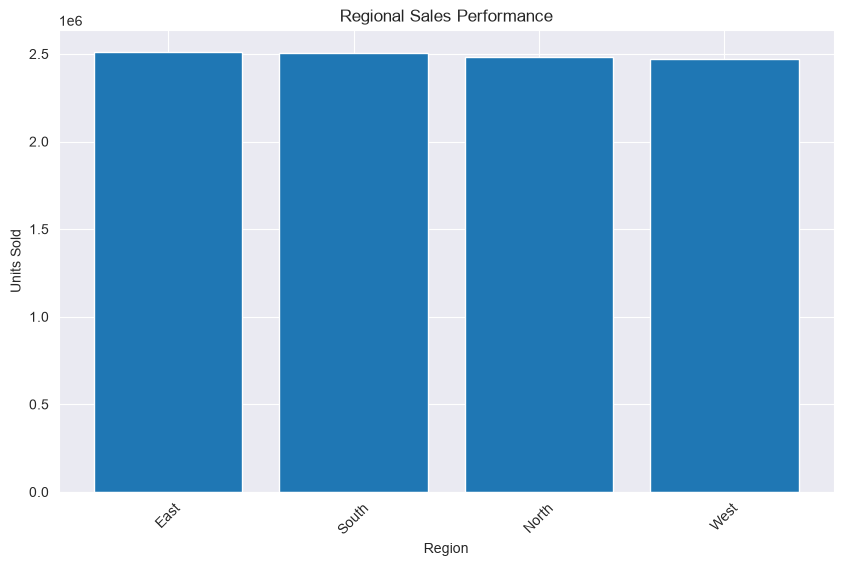

In [12]:
## Executive Chart 1: Regional Sales Performance

import matplotlib.pyplot as plt
import pandas as pd

regional_sales = pd.read_sql("""
SELECT
    Region,
    SUM("Units Sold") AS Units_Sold
FROM fact_inventory
GROUP BY Region
ORDER BY Units_Sold DESC
""", conn)

plt.figure(figsize=(10,6))

plt.bar(
    regional_sales["Region"],
    regional_sales["Units_Sold"]
)

plt.title("Regional Sales Performance")
plt.xlabel("Region")
plt.ylabel("Units Sold")

plt.xticks(rotation=45)

plt.show()

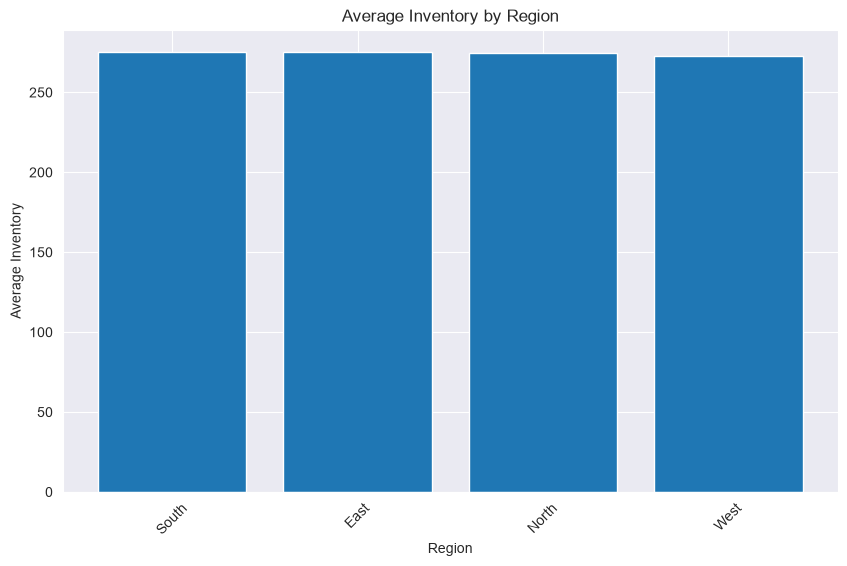

In [13]:
## Executive Chart 2: Regional Inventory Levels

inventory_region = pd.read_sql("""
SELECT
    Region,
    AVG("Inventory Level") AS Avg_Inventory
FROM fact_inventory
GROUP BY Region
ORDER BY Avg_Inventory DESC
""", conn)

plt.figure(figsize=(10,6))

plt.bar(
    inventory_region["Region"],
    inventory_region["Avg_Inventory"]
)

plt.title("Average Inventory by Region")
plt.xlabel("Region")
plt.ylabel("Average Inventory")

plt.xticks(rotation=45)

plt.show()

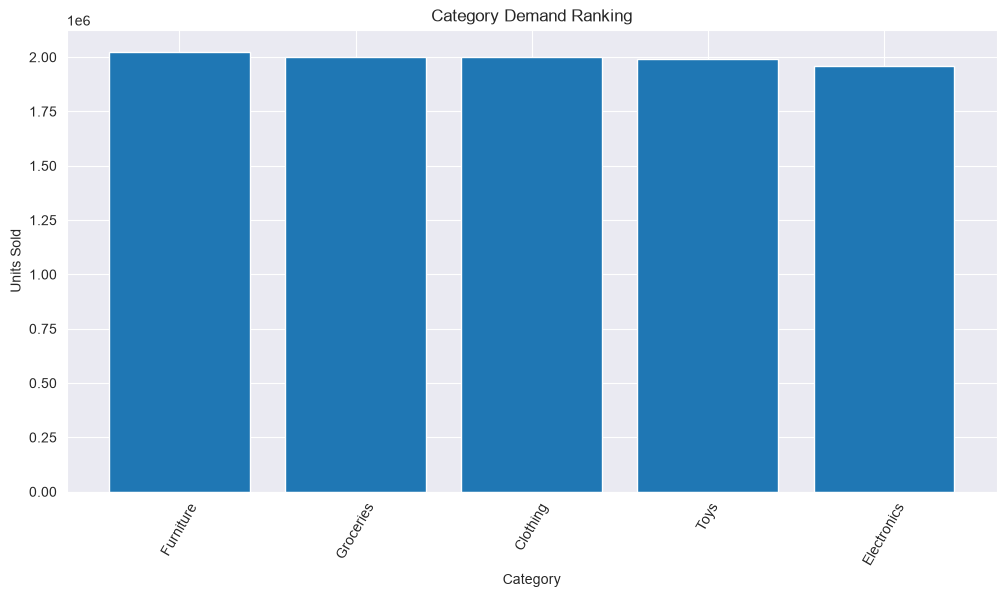

In [14]:
## Executive Chart 3: Category Performance

category_sales = pd.read_sql("""
SELECT
    Category,
    SUM("Units Sold") AS Units_Sold
FROM fact_inventory
GROUP BY Category
ORDER BY Units_Sold DESC
""", conn)

plt.figure(figsize=(12,6))

plt.bar(
    category_sales["Category"],
    category_sales["Units_Sold"]
)

plt.title("Category Demand Ranking")
plt.xlabel("Category")
plt.ylabel("Units Sold")

plt.xticks(rotation=60)

plt.show()

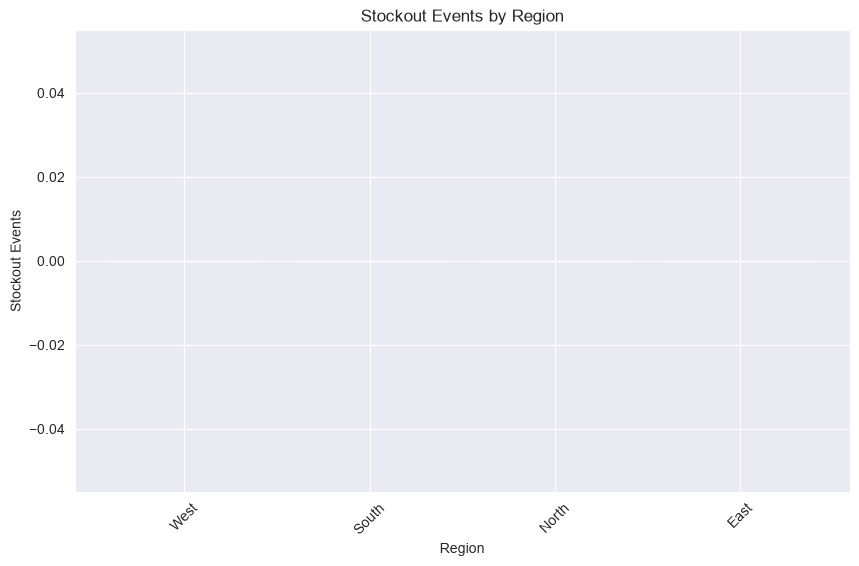

In [15]:
## Executive Chart 4: Stockout Risk by Region

stockouts = pd.read_sql("""
SELECT
    Region,
    SUM(
        CASE
            WHEN "Inventory Level" = 0
            THEN 1
            ELSE 0
        END
    ) AS Stockout_Events
FROM fact_inventory
GROUP BY Region
ORDER BY Stockout_Events DESC
""", conn)

plt.figure(figsize=(10,6))

plt.bar(
    stockouts["Region"],
    stockouts["Stockout_Events"],
    color="red"
)

plt.title("Stockout Events by Region")
plt.xlabel("Region")
plt.ylabel("Stockout Events")

plt.xticks(rotation=45)

plt.show()

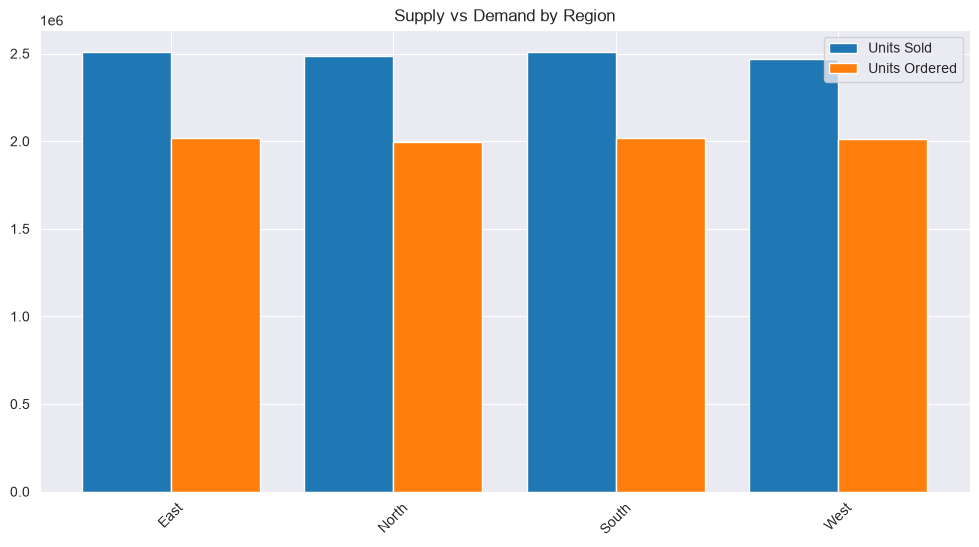

In [16]:
## Executive Chart 5: Units Sold vs Units Ordered

supply_balance = pd.read_sql("""
SELECT
    Region,
    SUM("Units Sold") AS Units_Sold,
    SUM("Units Ordered") AS Units_Ordered
FROM fact_inventory
GROUP BY Region
""", conn)

x = range(len(supply_balance))

plt.figure(figsize=(12,6))

plt.bar(
    x,
    supply_balance["Units_Sold"],
    width=.4,
    label="Units Sold"
)

plt.bar(
    [i+.4 for i in x],
    supply_balance["Units_Ordered"],
    width=.4,
    label="Units Ordered"
)

plt.xticks(
    [i+.2 for i in x],
    supply_balance["Region"],
    rotation=45
)

plt.legend()

plt.title("Supply vs Demand by Region")

plt.show()

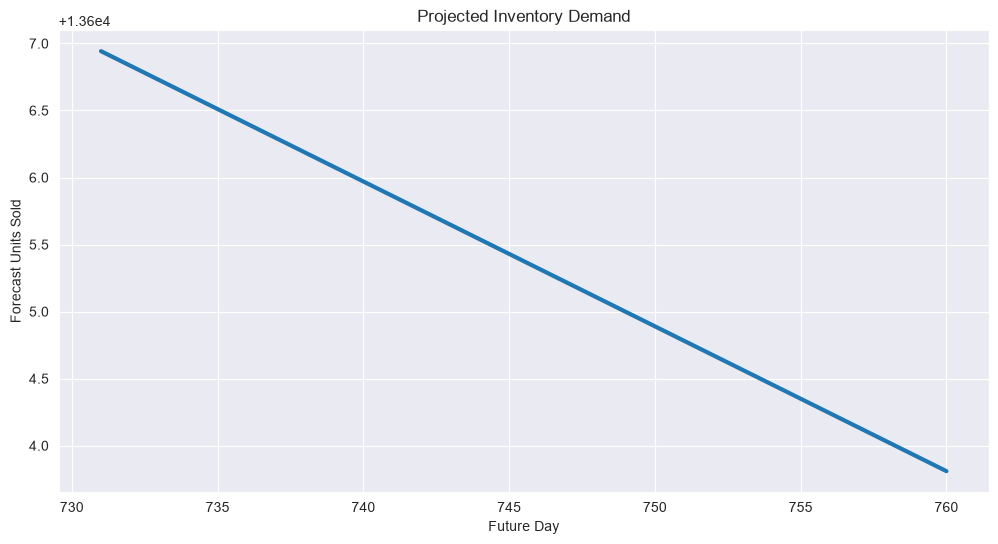

In [17]:
## Executive Chart 6: Forecast Trend

forecast_df = pd.read_csv(
    "inventory_forecast_output.csv"
)

plt.figure(figsize=(12,6))

plt.plot(
    forecast_df["Day_Number"],
    forecast_df["Forecast_Units_Sold"],
    linewidth=3
)

plt.title("Projected Inventory Demand")
plt.xlabel("Future Day")
plt.ylabel("Forecast Units Sold")

plt.grid(True)

plt.show()